[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/22_Deepfake_Spoofing_Detection/QSVM_AudioDeepfake_Amin2025.ipynb)

# QSVM for audio deepfake detection: Amin & Janeja (2025) step by step

**Paper.** Lisan Al Amin and Vandana P. Janeja, *Reliable Audio Deepfake Detection in Variable Conditions via Quantum-Kernel SVMs*, arXiv:2512.18797 [cs.SD], December 2025 (University of Maryland, Baltimore County). <https://arxiv.org/abs/2512.18797>

**What this notebook does.** The paper asks one narrow question: if you take a support vector machine (SVM) that classifies speech as *bona fide* or *spoofed*, and change **only the kernel** (a classical RBF/linear/polynomial kernel versus a quantum fidelity kernel simulated on a normal computer), does the equal-error rate (EER) go down? The notebook rebuilds that "kernel swap" end to end:

1. downloads small public subsets of four corpora (ASVspoof 2019 LA, ASVspoof 5, an ADD 2023 track 1.2 release, In-the-Wild),
2. turns every clip into a log-mel spectrogram, flattens it, min-max scales it, and reduces it with PCA fitted on the training part of each fold only,
3. runs stratified 5-fold cross-validation on balanced subsets of 200 clips (100 bona fide + 100 spoof), exactly as in the paper,
4. trains a classical SVM (linear/RBF/polynomial, tuned) and a quantum-kernel SVM (Z / ZZ / Pauli feature maps, 2-4 qubits, tuned) on identical inputs and identical folds,
5. reports accuracy, precision, recall, F1, EER, margin width and the paper's composite scores, side by side with the paper's Tables II-IV, and adds three checks the paper does not have: a nested (leak-free) hyper-parameter search, a noise / band-limiting test for "variable conditions", and a finite-shot emulation of quantum-hardware sampling.

**How to run.** Colab: *Runtime -> Run all* on a **CPU** runtime (no GPU, no IBM account needed). With `FAST_MODE = True` the whole notebook takes about 7 minutes (data download included); `FAST_MODE = False` uses the larger hyper-parameter grid and three independent 200-clip subsets per corpus (about 50 minutes on a laptop CPU: 4 corpora x 3 subsets x 5 folds x 52 quantum configurations). The installation cell may ask you to restart the session once: restart and run all again.

**What you get at the end.** A table of the paper's numbers next to ours with one verdict per claim (*reproduced*, *not reached*, *exceeded*, *cannot be checked*), figures (spectrograms, kernel matrices, ROC/DET curves, EER bars), and a critical reading of the paper plus exercises.

> **Important framing.** The quantum kernel here is computed by *exact classical simulation* of 2-4 qubits. No quantum hardware is used (neither in the paper nor here), so nothing in this notebook can show a quantum speed-up; it only tests whether this particular similarity function classifies spoofed speech better than classical kernels on small samples.

## The paper in one page

| Item | What the paper says |
|---|---|
| **Problem** | Detect synthetic (TTS / voice-conversion) speech when labelled data are scarce and recording conditions vary. Focus on a low false-positive rate (spoof accepted as genuine is the costly error, treated as the "positive" class being spoof, with FPR = share of bona fide flagged as spoof). |
| **Decision** | Binary: bona fide (+1) or deepfake (-1). Spoof is the positive class for precision / recall / EER. |
| **Method** | "Kernel swap": identical features, folds and SVM solver; only the Gram matrix changes. Classical kernels: linear, RBF, polynomial (sweep of `C`, `gamma`, degree). Quantum kernel: `k(z, z') = |<psi(z)|psi(z')>|^2` from Qiskit `ZZFeatureMap`, `PauliFeatureMap` or `ZFeatureMap`, 2-4 qubits, linear / full entanglement, `r` repetitions, computed exactly on a simulator (Aer, HPC cluster), passed to a classical SVM (`precomputed` kernel). Grid search of `C`, repetitions and entanglement with 5-fold CV. |
| **Data** | ASVspoof 2019 LA, ASVspoof 5 (2024), In-the-Wild, ADD 2023. For each corpus a **balanced subset of 200 clips (100 bona fide, 100 spoof)**, stratified 5-fold cross-validation, same folds for both models. |
| **Preprocessing** | Waveform -> mel-spectrogram -> flatten -> min-max scale (training statistics) -> PCA to `d in {2, 4, 6, 8}` (fitted per fold, training part only). |
| **Metrics** | Accuracy, precision, recall, F1 (weighted, since recall equals accuracy in Table II), EER, margin width `gamma = 2/||w||`, composite "separability" and "security" scores, two-sample t-tests and Cohen's d. Mean +- std over the five folds. |
| **Headline claims** | Table II EERs, QSVM vs SVM: ASVspoof 2019 **0.346 vs 0.399**, ASVspoof 5 **0.183 vs 0.299**, In-the-Wild **0.355 vs 0.413**, ADD23 **0.081 vs 0.188**; QSVM also has higher accuracy on three corpora (66.68 vs 65.94, 78.93 vs 76.87, 92.45 vs 88.75; In-the-Wild 63.47 vs 63.71 is "comparable"), smaller fold-to-fold spread, a smaller raw margin (Table III), large Cohen's d (Table IV). Best QSVMs use 3-4 qubits with ZZ or Pauli maps. |
| **Hardware** | None. The text only says the kernel "can be computed on hardware"; all kernels were simulated. |

### What follows the paper and what had to be chosen

The paper leaves many details open (exact subsets, mel settings, grids, how the "SVM" row is chosen, which ADD 2023 release). Every choice is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| ASVspoof 2019 LA | LA subset, 200 clips | Evaluation partition, Hugging Face mirror `SpeechAntiSpoofingBenchmarks/ASVspoof2019_LA` (ODC-By), first 100 bona fide + 100 spoof clips of shard 0 |
| ASVspoof 5 | Track-1 style data, many codecs | Evaluation partition, mirror `SpeechAntiSpoofingBenchmarks/ASVspoof5` (ODC-By), shard 0; the `codec` field of each clip is kept for analysis |
| In-the-Wild | uncontrolled real-world set | `SpeechAntiSpoofingBenchmarks/InTheWild` (Apache-2.0), shard 0 |
| ADD23 | "ADD 2023 challenge", subset unspecified | **Substitution:** the official Track 1.2 *development* release on Zenodo (record 12151404, CC BY-NC-ND 4.0), streamed from the start of the tar file; the R1 test audio used by the Arena is not redistributed |
| Subset selection | not described | first clips in the (shuffled) shard order, no speaker control; `N_REPEATS` independent subsets of 200 |
| Mel-spectrogram | unspecified | 3 s crop (shorter clips tiled), 16 kHz, `n_fft=512`, hop 256, 40 mel bands, dB with 80 dB floor, flattened to 7520 values |
| PCA dimension / qubits | `d in {2,4,6,8}`, 2-4 qubits | `d = number of qubits in {2, 3, 4}` for both models (one feature per qubit) |
| Feature maps | ZZ, Pauli, Z; linear / full; `r` reps | Qiskit 2.x `z_feature_map`, `zz_feature_map`, `pauli_feature_map(paulis=["Y","ZZ"])`; grids in the config cell |
| Angle scaling | not stated | `MinMaxScaler((0, pi))` on the PCA outputs, fitted on the training split, test clipped; an extra bandwidth multiplier is tuned in the grid |
| Classical SVM | linear / RBF / poly, swept | same grid style, run through the same precomputed-kernel code path on the same angle features |
| Model selection | "grid search with 5-fold CV" (apparently on the same folds) | **Nested**: grid chosen by 3-fold CV inside each training fold only; the outer test fold is never used for selection |
| EER | interpolated ROC crossing | same, per fold, then mean +- std (pooled out-of-fold EER also reported) |
| Margin / composite scores | formulas (7)-(9), arbitrary units | margin computed in the RKHS from the dual coefficients; composite scores computed with percentages and reported, but the paper's exact scaling is unclear and the paper itself plans to retire them |

In [1]:
# Colab already has numpy, pandas, scikit-learn, scipy, matplotlib, pyarrow, huggingface_hub, soundfile.
# We only pin the Qiskit stack that was tested for this notebook (the kernel is simulated exactly,
# so Aer and IBM runtime are not needed). A session restart may be required after the first install.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
try:
    import qiskit, qiskit_machine_learning, soundfile, huggingface_hub, pyarrow  # noqa: F401
    _READY = qiskit.__version__ == "2.5.2"
except Exception:
    _READY = False
if IN_COLAB or not _READY:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "qiskit==2.5.2", "qiskit-machine-learning==0.9.1", "pylatexenc",
                           "soundfile", "huggingface_hub", "pyarrow", "requests"])
    print("Installed. If imports below fail, use Runtime -> Restart session and Run all again.")
else:
    print("Qiskit stack already available; nothing to install.")

Qiskit stack already available; nothing to install.


In [2]:
# ---------------------------------------------------------------- configuration
SEED = 42
FAST_MODE = False            # True: about 10 min (small grid, 1 subset of 200 clips per corpus)
                            # False: larger grid + 3 independent subsets per corpus (about 1 hour)
IBM_TOKEN = ""              # not used: the paper simulates the kernel; no real-hardware cell exists

# datasets (keys follow the paper's names)
DATASETS = ["ASVspoof2019_LA", "ASVspoof5", "ADD23", "InTheWild"]
N_PER_CLASS = 100           # paper: 100 bona fide + 100 spoof per corpus
N_REPEATS = 1 if FAST_MODE else 3   # CHOICE: independent 200-clip subsets per corpus (paper: one)
N_FOLDS = 5                 # paper: stratified 5-fold CV, same folds for SVM and QSVM
INNER_FOLDS = 3             # CHOICE: inner CV (inside each training fold) used to pick hyper-parameters

# audio / mel front end  (CHOICE: the paper does not give these)
SR = 16000
CLIP_SECONDS = 3.0
N_FFT, HOP, N_MELS = 512, 256, 40
TOP_DB = 80.0
NOISE_SNRS_DB = [20, 10]    # extension for "variable conditions": white noise at these SNRs
LOWPASS_HZ = 4000           # extension: telephone-like band limiting

# model grids
D_GRID = [2, 3, 4]          # PCA dimension = number of qubits (paper: 2-4 qubits)
C_GRID = [0.1, 1.0, 10.0, 100.0]
if FAST_MODE:
    Q_REPS, Q_ENTS, Q_SCALES = [1, 2], ["linear"], [1.0]
else:
    Q_REPS, Q_ENTS, Q_SCALES = [1, 2], ["linear", "full"], [0.5, 1.0]
RBF_GAMMAS = [0.05, 0.2, 1.0]
POLY_DEGREES = [2, 3]

SHOTS = 1024                # finite-shot emulation of hardware sampling (extension)
DATA_DIR = "qc219_data"     # cache for downloaded subsets and features
HF_REPO = "SpeechAntiSpoofingBenchmarks"
ADD_URL = "https://zenodo.org/api/records/12151404/files/track1_2-dev.tar.gz/content"
ADD_URL_FALLBACK = "https://zenodo.org/api/records/12151404/files/track1_2-train.tar.gz/content"

PAPER_NAMES = {"ASVspoof2019_LA": "ASVspoof 2019 LA", "ASVspoof5": "ASVspoof 5 (2024)",
               "ADD23": "ADD23", "InTheWild": "In-the-Wild"}
print(f"FAST_MODE={FAST_MODE}, N_REPEATS={N_REPEATS}, quantum grid: reps={Q_REPS}, ent={Q_ENTS}, scales={Q_SCALES}")

FAST_MODE=False, N_REPEATS=3, quantum grid: reps=[1, 2], ent=['linear', 'full'], scales=[0.5, 1.0]


In [3]:
import os, io, time, json, math, tarfile, warnings, itertools, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests, soundfile as sf
import scipy, scipy.signal
from scipy.optimize import brentq
from scipy.interpolate import interp1d
from scipy import stats
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_curve,
                             confusion_matrix)
from sklearn.metrics.pairwise import rbf_kernel, polynomial_kernel
import qiskit, qiskit_machine_learning
from qiskit.circuit.library import zz_feature_map, z_feature_map, pauli_feature_map
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.utils import algorithm_globals

warnings.filterwarnings("ignore")
algorithm_globals.random_seed = SEED
RNG = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| sklearn", sklearn.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| soundfile", sf.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | sklearn 1.9.1 | numpy 2.5.4 | scipy 1.18.1 | soundfile 0.14.0


## 1. Data: four corpora, 200 clips each

The paper evaluates four public corpora but, because a quantum-kernel Gram matrix needs `O(N^2)` simulations, it uses only **200 clips per corpus (100 bona fide, 100 spoof)**. We do the same, downloading only what we need:

* **ASVspoof 2019 LA, ASVspoof 5, In-the-Wild** are available as Parquet shards (FLAC audio inside) on Hugging Face. The shards are shuffled and organised in row groups of 100 clips, so we read row groups over HTTP range requests until we have enough clips of each class: a few tens of megabytes instead of the multi-gigabyte archives.
* **ADD 2023 track 1.2** audio is only released as large tar archives on Zenodo. A gzip tar can be *streamed*: we read the label file at the beginning, skip the spectrogram `.mat` files that follow, and stop as soon as we hold 100 genuine and 100 fake WAV files (about 30 s).

Labels: **0 = bona fide, 1 = spoof** (spoof is the positive class, as in the paper). Everything is cached in `DATA_DIR` after the first run.

In [4]:
def tile_crop(x, n):
    """Crop to n samples, or tile (wrap) shorter clips. CHOICE: wrapping instead of zero padding, so clip
    length is not leaked by a run of exact zeros."""
    x = np.asarray(x, dtype=np.float32)
    if x.ndim > 1:
        x = x.mean(axis=1)
    if len(x) >= n:
        return x[:n]
    return np.tile(x, int(math.ceil(n / len(x))))[:n]

def lead_silence_seconds(x, sr, db=-40.0):
    """Seconds of near-silence at the start (RMS in 10 ms frames below `db` relative to the loudest frame)."""
    fl = int(0.01 * sr)
    n = len(x) // fl
    if n == 0:
        return 0.0
    rms = np.sqrt((x[: n * fl].reshape(n, fl) ** 2).mean(1)) + 1e-12
    idx = np.nonzero(rms > rms.max() * 10 ** (db / 20))[0]
    return float(idx[0] * 0.01) if len(idx) else float(n * 0.01)

def clip_record(x, sr, uid, label, meta):
    assert sr == SR, f"expected {SR} Hz, got {sr}"
    x = np.asarray(x, dtype=np.float32)
    if x.ndim > 1:
        x = x.mean(axis=1)
    return dict(wave=tile_crop(x, int(CLIP_SECONDS * SR)), label=int(label), uid=uid, meta=meta,
                dur=len(x) / sr, lead=lead_silence_seconds(x, sr),
                rms_db=float(20 * np.log10(np.sqrt((x ** 2).mean()) + 1e-9)))

def load_hf_subset(repo, need, shards=("data/test-00000-of-00009.parquet",)):
    """Read row groups of a Hugging Face Parquet shard until `need` clips of each class are found."""
    import pyarrow.parquet as pq
    from huggingface_hub import HfFileSystem
    fs = HfFileSystem()
    last_err = None
    for shard in shards:                      # fallback = the next shard in the list
        try:
            pf = pq.ParquetFile(fs.open(f"datasets/{HF_REPO}/{repo}/{shard}", "rb"))
            got = {0: [], 1: []}
            for g in range(pf.metadata.num_row_groups):
                for r in pf.read_row_group(g, columns=["path", "audio", "label", "notes"]).to_pylist():
                    if len(got[r["label"]]) < need:
                        x, sr = sf.read(io.BytesIO(r["audio"]["bytes"]), dtype="float32")
                        got[r["label"]].append(clip_record(x, sr, r["path"], r["label"], r["notes"]))
                if all(len(v) >= need for v in got.values()):
                    return got
            last_err = RuntimeError(f"shard {shard} did not hold {need} clips of each class")
        except Exception as e:                 # network problem etc. -> try next shard
            last_err = e
    raise RuntimeError(f"could not load {repo}: {last_err}")

def load_add_subset(need):
    """Stream the ADD 2023 track 1.2 tar.gz from Zenodo; labels come first, then WAVs."""
    last_err = None
    for url in (ADD_URL, ADD_URL_FALLBACK):
        try:
            resp = requests.get(url, stream=True, timeout=120)
            resp.raise_for_status()
            tf = tarfile.open(fileobj=resp.raw, mode="r|gz")
            labels, got = {}, {0: [], 1: []}
            for m in tf:
                base = m.name.split("/")[-1]
                if base == "label.txt" and not base.startswith("._"):
                    for line in tf.extractfile(m).read().decode().splitlines():
                        a, b = line.split()
                        labels[a] = 0 if b == "genuine" else 1
                elif base.endswith(".wav") and not base.startswith("._") and base in labels:
                    y = labels[base]
                    if len(got[y]) < need:
                        x, sr = sf.read(io.BytesIO(tf.extractfile(m).read()), dtype="float32")
                        got[y].append(clip_record(x, sr, base, y, json.dumps({"split": "dev"})))
                    if all(len(v) >= need for v in got.values()):
                        resp.close()
                        return got
            last_err = RuntimeError("archive ended before enough clips were found")
        except Exception as e:
            last_err = e
    raise RuntimeError(f"could not stream ADD23: {last_err}")

def fetch_clips(name, n_repeats):
    need = N_PER_CLASS * n_repeats
    if name == "ASVspoof2019_LA":
        return load_hf_subset("ASVspoof2019_LA", need, ("data/test-00000-of-00009.parquet", "data/test-00001-of-00009.parquet"))
    if name == "ASVspoof5":
        return load_hf_subset("ASVspoof5", need, ("data/test-00000-of-00200.parquet", "data/test-00001-of-00200.parquet"))
    if name == "InTheWild":
        return load_hf_subset("InTheWild", need, ("data/test-00000-of-00008.parquet", "data/test-00001-of-00008.parquet"))
    if name == "ADD23":
        return load_add_subset(need)
    raise ValueError(name)

## 2. Features: log-mel spectrogram, flattened

Following the paper's Eq. (6), every waveform becomes `S(t, m) = log( sum_f Mel_m(f) |X(t, f)|^2 + eps )`, where `X` is the short-time Fourier transform and `Mel_m` the mel filter bank. We implement it in plain NumPy (no librosa needed): Hann-windowed frames, `rfft`, a triangular mel filter bank between 0 and 8 kHz, conversion to decibels with an 80 dB floor, then flatten to a 7520-dimensional vector. The same function is later applied to *degraded* copies of each clip (white noise, band-limiting) for the "variable conditions" test.

Besides the spectrogram, each clip keeps three cheap metadata numbers (original duration, leading silence, loudness) that we use **only** for a shortcut check later; they never enter the models.

In [5]:
def mel_filterbank(sr=SR, n_fft=N_FFT, n_mels=N_MELS, fmin=0.0, fmax=None):
    fmax = fmax or sr / 2
    hz2mel = lambda f: 2595.0 * np.log10(1.0 + f / 700.0)
    mel2hz = lambda m: 700.0 * (10 ** (m / 2595.0) - 1.0)
    pts = mel2hz(np.linspace(hz2mel(fmin), hz2mel(fmax), n_mels + 2))
    freqs = np.linspace(0, sr / 2, n_fft // 2 + 1)
    fb = np.zeros((n_mels, len(freqs)), dtype=np.float32)
    for i in range(n_mels):
        lo, ce, hi = pts[i], pts[i + 1], pts[i + 2]
        up = (freqs - lo) / (ce - lo)
        down = (hi - freqs) / (hi - ce)
        fb[i] = np.clip(np.minimum(up, down), 0, None)
    return fb

MEL_FB = mel_filterbank()
HANN = np.hanning(N_FFT + 1)[:-1].astype(np.float32)

def log_mel(x):
    """Waveform (fixed length) -> flattened dB mel-spectrogram, Eq. (6) of the paper (in dB, 80 dB floor)."""
    xp = np.pad(x, (N_FFT // 2, N_FFT // 2), mode="reflect")
    frames = np.lib.stride_tricks.sliding_window_view(xp, N_FFT)[::HOP] * HANN
    power = np.abs(np.fft.rfft(frames, axis=1)) ** 2            # (T, F)
    mel = power @ MEL_FB.T                                       # (T, M)
    db = 10.0 * np.log10(mel + 1e-10)
    db = np.maximum(db, db.max() - TOP_DB)
    return db.astype(np.float32)                                 # (T, M)

def add_white_noise(x, snr_db, rng):
    p = float((x ** 2).mean()) + 1e-12
    return (x + rng.normal(0.0, math.sqrt(p / 10 ** (snr_db / 10)), size=x.shape)).astype(np.float32)

LOWPASS_SOS = scipy.signal.butter(8, LOWPASS_HZ / (SR / 2), btype="low", output="sos")
def band_limit(x):
    return scipy.signal.sosfilt(LOWPASS_SOS, x).astype(np.float32)

COND_NAMES = ["clean"] + [f"noise {s} dB" for s in NOISE_SNRS_DB] + [f"low-pass {LOWPASS_HZ // 1000} kHz"]

def build_dataset(name, n_repeats):
    """Return dict with arrays for `n_repeats` balanced subsets (repeat r = clips r*100..r*100+99 of each class)."""
    cache = os.path.join(DATA_DIR, f"{name}_R{n_repeats}_{CLIP_SECONDS}s_{N_MELS}mel.npz")
    if os.path.exists(cache):
        z = np.load(cache, allow_pickle=True)
        return {k: z[k] for k in z.files}
    t0 = time.time()
    got = fetch_clips(name, n_repeats)
    t1 = time.time()
    recs, rep = [], []
    for r in range(n_repeats):
        for lab in (0, 1):
            for c in got[lab][r * N_PER_CLASS:(r + 1) * N_PER_CLASS]:
                recs.append(c); rep.append(r)
    rng = np.random.default_rng(SEED)
    X = {c: [] for c in COND_NAMES}
    for c in recs:
        w = c["wave"]
        X["clean"].append(log_mel(w).ravel())
        for s in NOISE_SNRS_DB:
            X[f"noise {s} dB"].append(log_mel(add_white_noise(w, s, rng)).ravel())
        X[f"low-pass {LOWPASS_HZ // 1000} kHz"].append(log_mel(band_limit(w)).ravel())
    out = dict(
        y=np.array([c["label"] for c in recs]), rep=np.array(rep),
        uid=np.array([c["uid"] for c in recs]), meta=np.array([c["meta"] for c in recs]),
        dur=np.array([c["dur"] for c in recs]), lead=np.array([c["lead"] for c in recs]),
        rms_db=np.array([c["rms_db"] for c in recs]),
        example_wave=np.stack([got[0][0]["wave"], got[1][0]["wave"]]),
    )
    for c in COND_NAMES:
        out["X__" + c] = np.stack(X[c]).astype(np.float32)
    np.savez_compressed(cache, **out)
    print(f"  {name}: download {t1 - t0:.0f}s, features {time.time() - t1:.0f}s, cached to {cache}")
    return out

In [6]:
DATA = {}
t0 = time.time()
for name in DATASETS:
    DATA[name] = build_dataset(name, N_REPEATS)
    d = DATA[name]
    print(f"{PAPER_NAMES[name]:18s} clips={len(d['y'])}  bona fide={int((d['y']==0).sum())}  spoof={int((d['y']==1).sum())}  "
          f"feature dim={d['X__clean'].shape[1]}  median dur bona/spoof = "
          f"{np.median(d['dur'][d['y']==0]):.2f}s / {np.median(d['dur'][d['y']==1]):.2f}s")
print(f"data ready in {time.time() - t0:.0f}s")
# ASVspoof 5 keeps its codec label: how varied are the recording conditions in our 200 clips?
codec = [json.loads(m).get("codec", "-") for m in DATA["ASVspoof5"]["meta"]]
print("ASVspoof 5 codec field in the subset:", dict(collections.Counter(codec).most_common(8)), "...")

  ASVspoof2019_LA: download 24s, features 24s, cached to qc219_data\ASVspoof2019_LA_R3_3.0s_40mel.npz
ASVspoof 2019 LA   clips=600  bona fide=300  spoof=300  feature dim=7520  median dur bona/spoof = 3.20s / 2.65s


  ASVspoof5: download 16s, features 21s, cached to qc219_data\ASVspoof5_R3_3.0s_40mel.npz
ASVspoof 5 (2024)  clips=600  bona fide=300  spoof=300  feature dim=7520  median dur bona/spoof = 7.19s / 7.00s


  ADD23: download 61s, features 21s, cached to qc219_data\ADD23_R3_3.0s_40mel.npz
ADD23              clips=600  bona fide=300  spoof=300  feature dim=7520  median dur bona/spoof = 2.92s / 2.96s


  InTheWild: download 11s, features 24s, cached to qc219_data\InTheWild_R3_3.0s_40mel.npz
In-the-Wild        clips=600  bona fide=300  spoof=300  feature dim=7520  median dur bona/spoof = 2.86s / 4.38s
data ready in 202s
ASVspoof 5 codec field in the subset: {'-': 113, 'C01': 54, 'C07': 51, 'C06': 48, 'C05': 47, 'C08': 46, 'C11': 45, 'C10': 42} ...


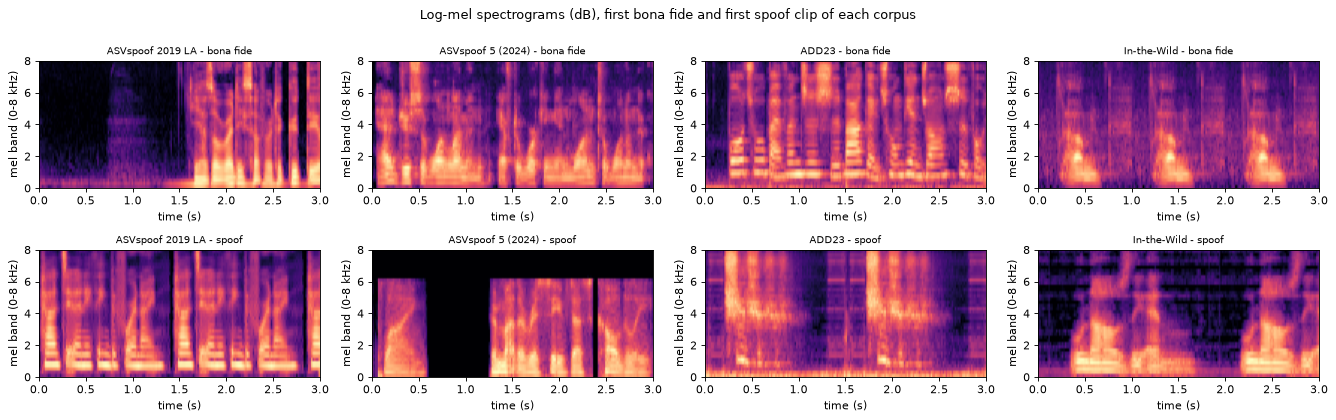

In [7]:
fig, axes = plt.subplots(2, len(DATASETS), figsize=(4.2 * len(DATASETS), 5.2))
for j, name in enumerate(DATASETS):
    d = DATA[name]
    for i, lab in enumerate(["bona fide", "spoof"]):
        k = int(np.nonzero(d["y"] == i)[0][0])
        S = d["X__clean"][k].reshape(-1, N_MELS).T
        ax = axes[i, j]
        im = ax.imshow(S, origin="lower", aspect="auto", cmap="magma", extent=[0, CLIP_SECONDS, 0, 8])
        ax.set_title(f"{PAPER_NAMES[name]} - {lab}", fontsize=9)
        ax.set_xlabel("time (s)"); ax.set_ylabel("mel band (0-8 kHz)"); ax.grid(False)
plt.suptitle("Log-mel spectrograms (dB), first bona fide and first spoof clip of each corpus", y=1.0)
plt.tight_layout(); plt.show()

## 3. The kernel swap: same features, same SVM, different Gram matrix

An SVM needs only a **Gram matrix** `K[i, j] = k(z_i, z_j)`, a table of pairwise similarities. Scikit-learn's `SVC(kernel="precomputed")` takes that table directly, so we can feed it either

* a classical kernel: linear `z.z'`, RBF `exp(-gamma |z-z'|^2)`, or polynomial `(z.z'/d + 1)^degree`, or
* the **quantum fidelity kernel** `k(z, z') = |<psi(z)|psi(z')>|^2`, where `|psi(z)> = U(z)|0...0>` is the state prepared by a feature-map circuit `U` that writes the (PCA-reduced) feature vector `z` into rotation angles of `d` qubits.

We simulate the circuits exactly with `qiskit.quantum_info.Statevector` (one statevector per clip, then `K = |S S^dagger|^2` with a single matrix product). The next cell draws one feature map and verifies that this hand-made Gram matrix equals Qiskit's own `FidelityStatevectorKernel`, the object that Qiskit Machine Learning's `QSVC` uses.

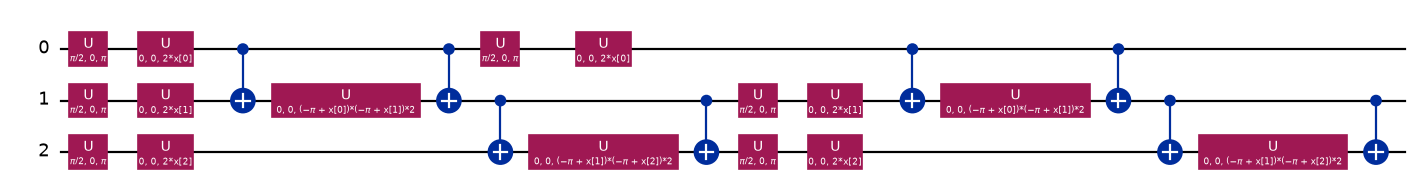

hand-made Gram == FidelityStatevectorKernel: True | diag all 1: True


In [8]:
def get_fm_raw(kind, ent, reps, d):
    # CHOICE: Z / ZZ / Pauli feature maps (Qiskit 2.x function-style circuit library), as listed in the paper.
    if kind == "Z":
        return z_feature_map(d, reps=reps)
    if kind == "ZZ":
        return zz_feature_map(d, reps=reps, entanglement=ent)
    return pauli_feature_map(d, reps=reps, paulis=["Y", "ZZ"], entanglement=ent)   # CHOICE: Pauli strings Y and ZZ

_FM = {}
def get_fm(kind, ent, reps, d):
    key = (kind, ent, reps, d)
    if key not in _FM:
        _FM[key] = get_fm_raw(*key)
    return _FM[key]

def q_states(fm, A):
    """One exact statevector per row of A (angles in radians)."""
    return np.array([Statevector(fm.assign_parameters(a)).data for a in A])

def q_gram(S_a, S_b):
    return np.abs(S_a.conj() @ S_b.T) ** 2

# --- draw one feature map
fm_demo = get_fm("ZZ", "linear", 2, 3)
try:
    from IPython.display import display
    fig = fm_demo.decompose().draw("mpl", fold=-1)
    display(fig); plt.close(fig)
except Exception as e:
    print(fm_demo.decompose().draw("text"))

# --- hand-made Gram matrix versus Qiskit's FidelityStatevectorKernel
Ztest = np.random.default_rng(SEED).uniform(0, np.pi, size=(20, 3))
K_hand = q_gram(q_states(fm_demo, Ztest), q_states(fm_demo, Ztest))
K_qiskit = FidelityStatevectorKernel(feature_map=fm_demo).evaluate(Ztest, Ztest)
print("hand-made Gram == FidelityStatevectorKernel:", np.allclose(K_hand, K_qiskit, atol=1e-8),
      "| diag all 1:", np.allclose(np.diag(K_hand), 1.0))

## 4. Pipeline per fold (nothing from the test fold is ever fitted)

For each of the 5 stratified folds we **fit on the 160 training clips only**:

1. `MinMaxScaler` on the 7520 spectrogram values (paper: "min-max scaled using training-set statistics"),
2. `PCA` to at most 4 components (the first `d` components are nested, so `d = 2, 3, 4` come from one fit),
3. `MinMaxScaler((0, pi))` on the retained components so they can be used as rotation angles; test values are clipped to `[0, pi]`. **Both models receive these same angle features** ("identical features" in the paper).

Hyper-parameters (`d`, feature map, entanglement, repetitions, bandwidth, `C` for the quantum side; `d`, kernel type, `gamma` / degree, `C` for the classical side) are chosen by **3-fold cross-validation inside the training fold**, maximising accuracy (AUC breaks ties). This is stricter than the paper, which seems to run its grid search on the same 5 folds it reports. Both families get exactly the same machinery, but the quantum grid is larger (more configurations), as in the paper: that is a degree of freedom favouring the QSVM that the reader should keep in mind.

In [9]:
# ------------------------------------------------------------ grids
Q_CFGS = []   # (kind, entanglement, reps, d, bandwidth scale)
for d in D_GRID:
    for sc in Q_SCALES:
        for reps in Q_REPS:
            Q_CFGS.append(("Z", "-", reps, d, sc))
            for ent in Q_ENTS:
                if d == 2 and ent == "full":
                    continue                       # for 2 qubits linear == full entanglement
                Q_CFGS.append(("ZZ", ent, reps, d, sc))
                Q_CFGS.append(("Pauli", ent, reps, d, sc))
C_CFGS = []   # (kernel, parameter, d)
for d in D_GRID:
    C_CFGS.append(("linear", None, d))
    C_CFGS += [("rbf", g, d) for g in RBF_GAMMAS]
    C_CFGS += [("poly", p, d) for p in POLY_DEGREES]
print(f"quantum configurations: {len(Q_CFGS)}, classical configurations: {len(C_CFGS)}, C values: {C_GRID}")

def classical_gram(cfg, A, B):
    kind, p, d = cfg
    if kind == "linear":
        return A @ B.T
    if kind == "rbf":
        return rbf_kernel(A, B, gamma=p)
    return polynomial_kernel(A, B, degree=p, gamma=1.0 / d, coef0=1.0)     # CHOICE: gamma = 1/d, coef0 = 1

# ------------------------------------------------------------ preprocessing, fitted on the training split only
def fit_pipeline(Xtr):
    s1 = MinMaxScaler().fit(Xtr)
    pca = PCA(n_components=max(D_GRID), random_state=SEED).fit(s1.transform(Xtr))
    Ztr = pca.transform(s1.transform(Xtr))
    ang = {d: MinMaxScaler((0, np.pi)).fit(Ztr[:, :d]) for d in D_GRID}
    return dict(s1=s1, pca=pca, ang=ang)

def transform(pipe, X, d):
    Z = pipe["pca"].transform(pipe["s1"].transform(X))[:, :d]
    return np.clip(pipe["ang"][d].transform(Z), 0.0, np.pi)

# ------------------------------------------------------------ metrics
def eer(y, s):
    """Equal error rate: ROC curve crossing FPR = FNR (linear interpolation), spoof = positive class."""
    fpr, tpr, _ = roc_curve(y, s)
    try:
        return float(brentq(lambda x: 1.0 - x - interp1d(fpr, tpr)(x), 0.0, 1.0))
    except Exception:
        i = int(np.argmin(np.abs((1 - tpr) - fpr)))
        return float((fpr[i] + 1 - tpr[i]) / 2)

def metrics(y, pred, score):
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="weighted", zero_division=0)   # weighted: recall == accuracy as in Table II
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(acc=100 * accuracy_score(y, pred), prec=100 * p, rec=100 * r, f1=100 * f,
                eer=eer(y, score), fpr=fp / max(fp + tn, 1), fnr=fn / max(fn + tp, 1))

def margin_width(svc, Ktr):
    """Geometric margin gamma = 2/||w||_H, with ||w||^2 = a^T K_sv a from the dual coefficients."""
    sv, a = svc.support_, svc.dual_coef_[0]
    return float(2.0 / np.sqrt(a @ Ktr[np.ix_(sv, sv)] @ a))

from sklearn.metrics import roc_auc_score
def select_hparams(grams, tr, y):
    """Inner CV inside the training fold only. Returns (score, cfg, C)."""
    inner = list(StratifiedKFold(INNER_FOLDS, shuffle=True, random_state=SEED).split(tr, y[tr]))
    ytr, best = y[tr], (-1.0, None, None)
    for cfg, K in grams.items():
        Ktr = K[np.ix_(tr, tr)]
        for C in C_GRID:
            accs, aucs = [], []
            for a, b in inner:
                m = SVC(kernel="precomputed", C=C, max_iter=200000).fit(Ktr[np.ix_(a, a)], ytr[a])
                s = m.decision_function(Ktr[np.ix_(b, a)])
                accs.append(np.mean((s > 0) == ytr[b])); aucs.append(roc_auc_score(ytr[b], s))
            sc = float(np.mean(accs)) + 1e-3 * float(np.mean(aucs))     # CHOICE: AUC only breaks accuracy ties
            if sc > best[0]:
                best = (sc, cfg, C)
    return best

def fold_splits(y, r):
    return list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED + r).split(np.zeros(len(y)), y))

quantum configurations: 52, classical configurations: 18, C values: [0.1, 1.0, 10.0, 100.0]


## 5. Stratified 5-fold cross-validation on all four corpora

The next cell is the experiment. For every corpus, subset and fold it

1. fits the preprocessing on the training clips,
2. builds every candidate Gram matrix (quantum: one statevector per clip per configuration; classical: closed-form kernels),
3. picks the best configuration of each family by inner cross-validation, refits and scores the held-out fold,
4. also trains two extra classical references on the same 4-dimensional inputs (a random forest and an untuned RBF SVM),
5. re-scores the *same trained models* on degraded copies of the test clips (white noise at 20 and 10 dB SNR, 4 kHz low-pass), which is our test of the paper's title word "variable conditions" (the paper itself only varies the corpus),
6. re-estimates the chosen quantum kernel from `SHOTS` measurement shots per entry (binomial sampling of the exact fidelity), which mimics what hardware would deliver minus device noise.

Progress is printed per corpus; the fast configuration needs several minutes of CPU.

In [10]:
RESULTS, OOF, ART = [], collections.defaultdict(lambda: ([], [])), {}

def fit_score(K_all, cfg_C, tr, te, y):
    C = cfg_C
    m = SVC(kernel="precomputed", C=C, max_iter=200000).fit(K_all[np.ix_(tr, tr)], y[tr])
    s = m.decision_function(K_all[np.ix_(te, tr)])
    return m, s

def run_fold(name, r, fold, tr, te, X, y, Xn):
    t0 = time.time()
    pipe = fit_pipeline(X[tr])
    Z = {d: transform(pipe, X, d) for d in D_GRID}
    # --- all candidate Gram matrices on the 200 clips (train-fitted pipeline applied to everybody)
    S_all, gq = {}, {}
    for cfg in Q_CFGS:
        kind, ent, reps, d, sc = cfg
        S_all[cfg] = q_states(get_fm(kind, ent, reps, d), Z[d] * sc)
        gq[cfg] = q_gram(S_all[cfg], S_all[cfg])
    gc = {cfg: classical_gram(cfg, Z[cfg[2]], Z[cfg[2]]) for cfg in C_CFGS}
    best = {"QSVM": select_hparams(gq, tr, y), "SVM": select_hparams(gc, tr, y)}
    rows = []
    def add(model, cond, y_te, s, **extra):
        pred = (s > 0).astype(int)
        rows.append(dict(ds=name, rep=r, fold=fold, model=model, cond=cond, **metrics(y_te, pred, s), **extra))
        OOF[(name, r, model, cond)][0].append(y_te); OOF[(name, r, model, cond)][1].append(s)
    y_te = y[te]
    fitted = {}
    for model, grams in (("QSVM", gq), ("SVM", gc)):
        cvsc, cfg, C = best[model]
        m, s = fit_score(grams[cfg], C, tr, te, y)
        gam = margin_width(m, grams[cfg][np.ix_(tr, tr)])
        d = cfg[3] if model == "QSVM" else cfg[2]
        add(model, "clean", y_te, s, margin=gam, cfg=str(cfg), C=C, d=d, cv=cvsc, n_sv=len(m.support_))
        fitted[model] = (cfg, C, m)
    # --- extra classical references on the same 4-d angle features
    dmax = max(D_GRID)
    rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1).fit(Z[dmax][tr], y[tr])
    add("RandomForest", "clean", y_te, rf.predict_proba(Z[dmax][te])[:, 1] - 0.5, margin=np.nan, cfg="n=200", C=np.nan, d=dmax, cv=np.nan, n_sv=0)
    sv = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED).fit(Z[dmax][tr], y[tr])
    add("SVC-rbf (default)", "clean", y_te, sv.decision_function(Z[dmax][te]), margin=np.nan, cfg="C=1,gamma=scale", C=1.0, d=dmax, cv=np.nan, n_sv=len(sv.support_))
    # --- variable conditions: same trained models, degraded test clips
    cfgq, Cq, mq = fitted["QSVM"]; kind, ent, reps, dq, scq = cfgq
    cfgc, Cc, mc = fitted["SVM"]
    for cond in COND_NAMES[1:]:
        Zq = transform(pipe, Xn[cond][te], dq) * scq
        Kq = q_gram(q_states(get_fm(kind, ent, reps, dq), Zq), S_all[cfgq][tr])
        add("QSVM", cond, y_te, mq.decision_function(Kq), margin=np.nan, cfg=str(cfgq), C=Cq, d=dq, cv=np.nan, n_sv=0)
        Zc = transform(pipe, Xn[cond][te], cfgc[2])
        Kc = classical_gram(cfgc, Zc, Z[cfgc[2]][tr])
        add("SVM", cond, y_te, mc.decision_function(Kc), margin=np.nan, cfg=str(cfgc), C=Cc, d=cfgc[2], cv=np.nan, n_sv=0)
    # --- finite shots: estimate every fidelity from SHOTS samples (binomial), symmetric, unit diagonal
    rng = np.random.default_rng(SEED + 1000 * r + fold)
    Ks = rng.binomial(SHOTS, np.clip(gq[cfgq], 0, 1)) / SHOTS
    Ks = np.triu(Ks, 1); Ks = Ks + Ks.T + np.eye(len(Ks))
    m, s = fit_score(Ks, Cq, tr, te, y)
    add("QSVM", f"{SHOTS} shots", y_te, s, margin=np.nan, cfg=str(cfgq), C=Cq, d=dq, cv=np.nan, n_sv=len(m.support_))
    if r == 0 and fold == 0:
        ART[name] = dict(Zq2=Z[2], y=y, tr=tr, te=te, Kq=gq[best["QSVM"][1]], Kc=gc[best["SVM"][1]],
                         cfgq=best["QSVM"][1], cfgc=best["SVM"][1], Z4=Z[dmax])
    return rows, time.time() - t0

T_START = time.time()
for name in DATASETS:
    d = DATA[name]
    for r in range(N_REPEATS):
        idx = np.nonzero(d["rep"] == r)[0]
        X, y = d["X__clean"][idx], d["y"][idx]
        Xn = {c: d["X__" + c][idx] for c in COND_NAMES[1:]}
        t0 = time.time()
        for fold, (tr, te) in enumerate(fold_splits(y, r)):
            rows, secs = run_fold(name, r, fold, tr, te, X, y, Xn)
            RESULTS += rows
        df_ = pd.DataFrame([x for x in RESULTS if x["ds"] == name and x["rep"] == r and x["cond"] == "clean"])
        g = df_.groupby("model")[["acc", "eer"]].mean()
        print(f"{PAPER_NAMES[name]:18s} rep {r}: {time.time() - t0:5.0f}s | "
              f"QSVM acc {g.loc['QSVM','acc']:.1f} EER {g.loc['QSVM','eer']:.3f} | SVM acc {g.loc['SVM','acc']:.1f} EER {g.loc['SVM','eer']:.3f}")
RES = pd.DataFrame(RESULTS)
print(f"total experiment time: {(time.time() - T_START) / 60:.1f} min, rows: {len(RES)}")

ASVspoof 2019 LA   rep 0:   225s | QSVM acc 89.0 EER 0.160 | SVM acc 88.5 EER 0.140


ASVspoof 2019 LA   rep 1:   234s | QSVM acc 82.0 EER 0.250 | SVM acc 83.5 EER 0.200


ASVspoof 2019 LA   rep 2:   228s | QSVM acc 89.0 EER 0.100 | SVM acc 90.0 EER 0.100


ASVspoof 5 (2024)  rep 0:   226s | QSVM acc 51.5 EER 0.500 | SVM acc 54.5 EER 0.490


ASVspoof 5 (2024)  rep 1:   233s | QSVM acc 58.0 EER 0.420 | SVM acc 62.0 EER 0.350


...

ADD23              rep 1:   213s | QSVM acc 84.0 EER 0.160 | SVM acc 85.0 EER 0.130


ADD23              rep 2:   219s | QSVM acc 80.0 EER 0.190 | SVM acc 82.0 EER 0.180


In-the-Wild        rep 0:   187s | QSVM acc 71.5 EER 0.290 | SVM acc 75.5 EER 0.250


In-the-Wild        rep 1:   226s | QSVM acc 70.0 EER 0.290 | SVM acc 73.0 EER 0.260


In-the-Wild        rep 2:   201s | QSVM acc 69.0 EER 0.300 | SVM acc 70.5 EER 0.310
total experiment time: 44.0 min, rows: 660


## 6. Table II: accuracy, precision, recall, F1 and EER (mean +- std over folds)

Precision, recall and F1 are weighted averages over the two classes (that is the only reading under which the paper's recall equals its accuracy). EER is computed per fold from the held-out scores and then averaged. With `N_REPEATS > 1` the mean and std are over all `5 x N_REPEATS` folds.

In [11]:
PAPER = {   # Table II (mean accuracy etc. in %, EER as fraction), Table II std for accuracy, Table III margin
 "ASVspoof2019_LA": {"QSVM": dict(acc=66.68, prec=68.11, rec=66.68, f1=66.11, eer=0.346, acc_sd=4.77, margin=0.7615),
                     "SVM":  dict(acc=65.94, prec=68.22, rec=65.94, f1=63.61, eer=0.399, acc_sd=6.62, margin=0.805)},
 "ASVspoof5":       {"QSVM": dict(acc=78.93, prec=79.93, rec=78.93, f1=78.73, eer=0.183, acc_sd=2.66, margin=0.966),
                     "SVM":  dict(acc=76.87, prec=75.68, rec=76.87, f1=75.19, eer=0.299, acc_sd=11.24, margin=1.050)},
 "InTheWild":       {"QSVM": dict(acc=63.47, prec=63.92, rec=63.47, f1=63.11, eer=0.355, acc_sd=4.35, margin=0.652),
                     "SVM":  dict(acc=63.71, prec=63.02, rec=63.71, f1=58.86, eer=0.413, acc_sd=9.47, margin=0.743)},
 "ADD23":           {"QSVM": dict(acc=92.45, prec=93.22, rec=92.45, f1=92.39, eer=0.081, acc_sd=3.85, margin=1.224),
                     "SVM":  dict(acc=88.75, prec=88.98, rec=88.75, f1=87.61, eer=0.188, acc_sd=16.22, margin=1.487)},
}
clean = RES[RES.cond == "clean"]
rows = []
for name in DATASETS:
    for model in ["QSVM", "SVM", "RandomForest", "SVC-rbf (default)"]:
        g = clean[(clean.ds == name) & (clean.model == model)]
        rows.append({"Dataset": PAPER_NAMES[name], "Model": model,
                     **{k: f"{g[k].mean():.2f} +- {g[k].std(ddof=1):.2f}" for k in ["acc", "prec", "rec", "f1"]},
                     "EER": f"{g['eer'].mean():.3f} +- {g['eer'].std(ddof=1):.3f}"})
TABLE2 = pd.DataFrame(rows).rename(columns={"acc": "Acc. (%)", "prec": "Prec. (%)", "rec": "Recall (%)", "f1": "F1 (%)"})
display(TABLE2.style.hide(axis="index"))

# pooled out-of-fold EER (one threshold-free number per subset, less noisy than 40-clip folds)
pooled = []
for name in DATASETS:
    for model in ["QSVM", "SVM"]:
        v = [eer(np.concatenate(OOF[(name, r, model, "clean")][0]), np.concatenate(OOF[(name, r, model, "clean")][1])) for r in range(N_REPEATS)]
        pooled.append({"Dataset": PAPER_NAMES[name], "Model": model, "pooled out-of-fold EER (mean over subsets)": round(float(np.mean(v)), 3)})
display(pd.DataFrame(pooled).pivot(index="Dataset", columns="Model", values="pooled out-of-fold EER (mean over subsets)").loc[[PAPER_NAMES[n] for n in DATASETS]])

Dataset,Model,Acc. (%),Prec. (%),Recall (%),F1 (%),EER
ASVspoof 2019 LA,QSVM,86.67 +- 6.10,88.29 +- 4.90,86.67 +- 6.10,86.43 +- 6.53,0.170 +- 0.100
ASVspoof 2019 LA,SVM,87.33 +- 5.78,88.67 +- 5.12,87.33 +- 5.78,87.17 +- 5.99,0.147 +- 0.083
ASVspoof 2019 LA,RandomForest,85.50 +- 9.22,86.16 +- 9.36,85.50 +- 9.22,85.44 +- 9.24,0.151 +- 0.096
ASVspoof 2019 LA,SVC-rbf (default),87.83 +- 5.42,89.57 +- 4.29,87.83 +- 5.42,87.63 +- 5.66,0.147 +- 0.077
ASVspoof 5 (2024),QSVM,54.17 +- 8.95,54.53 +- 9.66,54.17 +- 8.95,53.35 +- 9.11,0.463 +- 0.083
ASVspoof 5 (2024),SVM,57.00 +- 7.75,57.39 +- 7.94,57.00 +- 7.75,56.01 +- 8.30,0.430 +- 0.088
ASVspoof 5 (2024),RandomForest,57.83 +- 7.49,58.12 +- 7.79,57.83 +- 7.49,57.46 +- 7.60,0.442 +- 0.084
ASVspoof 5 (2024),SVC-rbf (default),58.00 +- 6.14,58.60 +- 6.53,58.00 +- 6.14,57.31 +- 6.23,0.403 +- 0.077
ADD23,QSVM,83.00 +- 6.42,83.49 +- 6.49,83.00 +- 6.42,82.94 +- 6.43,0.167 +- 0.075
ADD23,SVM,84.00 +- 5.41,84.53 +- 5.36,84.00 +- 5.41,83.93 +- 5.44,0.147 +- 0.067


Model,QSVM,SVM
Dataset,,
ASVspoof 2019 LA,0.173,0.150
ASVspoof 5 (2024),0.473,0.430
ADD23,0.163,0.160
In-the-Wild,0.300,0.293


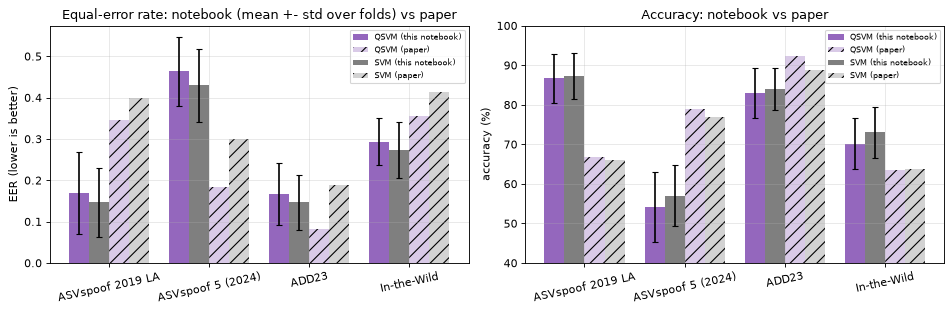

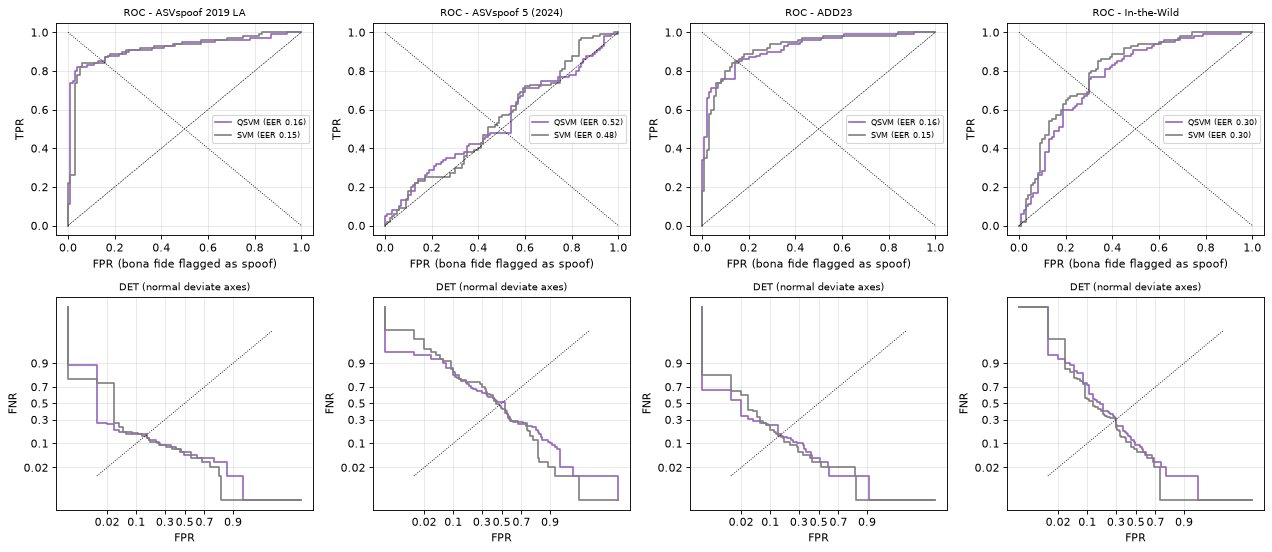

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(DATASETS)); w = 0.2
ax = axes[0]
for k, (model, col) in enumerate([("QSVM", "tab:purple"), ("SVM", "tab:gray")]):
    mu = [clean[(clean.ds == n) & (clean.model == model)].eer.mean() for n in DATASETS]
    sd = [clean[(clean.ds == n) & (clean.model == model)].eer.std(ddof=1) for n in DATASETS]
    ax.bar(x + (k - 1.5) * w, mu, w, yerr=sd, capsize=3, color=col, label=f"{model} (this notebook)")
    ax.bar(x + (k + 0.5) * w, [PAPER[n][model]["eer"] for n in DATASETS], w, color=col, alpha=0.35, hatch="//", label=f"{model} (paper)")
ax.set_xticks(x); ax.set_xticklabels([PAPER_NAMES[n] for n in DATASETS], rotation=12); ax.set_ylabel("EER (lower is better)")
ax.set_title("Equal-error rate: notebook (mean +- std over folds) vs paper"); ax.legend(fontsize=7)
ax = axes[1]
for k, (model, col) in enumerate([("QSVM", "tab:purple"), ("SVM", "tab:gray")]):
    mu = [clean[(clean.ds == n) & (clean.model == model)].acc.mean() for n in DATASETS]
    sd = [clean[(clean.ds == n) & (clean.model == model)].acc.std(ddof=1) for n in DATASETS]
    ax.bar(x + (k - 1.5) * w, mu, w, yerr=sd, capsize=3, color=col, label=f"{model} (this notebook)")
    ax.bar(x + (k + 0.5) * w, [PAPER[n][model]["acc"] for n in DATASETS], w, color=col, alpha=0.35, hatch="//", label=f"{model} (paper)")
ax.set_xticks(x); ax.set_xticklabels([PAPER_NAMES[n] for n in DATASETS], rotation=12); ax.set_ylabel("accuracy (%)"); ax.set_ylim(40, 100)
ax.set_title("Accuracy: notebook vs paper"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# ROC and DET from pooled out-of-fold scores (subset 0)
from scipy.stats import norm
fig, axes = plt.subplots(2, len(DATASETS), figsize=(4 * len(DATASETS), 7))
for j, name in enumerate(DATASETS):
    for model, col in [("QSVM", "tab:purple"), ("SVM", "tab:gray")]:
        yy = np.concatenate(OOF[(name, 0, model, "clean")][0]); ss = np.concatenate(OOF[(name, 0, model, "clean")][1])
        fpr, tpr, _ = roc_curve(yy, ss)
        axes[0, j].plot(fpr, tpr, color=col, label=f"{model} (EER {eer(yy, ss):.2f})")
        fnr = np.clip(1 - tpr, 1e-3, 1 - 1e-3); f2 = np.clip(fpr, 1e-3, 1 - 1e-3)
        axes[1, j].plot(norm.ppf(f2), norm.ppf(fnr), color=col)
    axes[0, j].plot([0, 1], [1, 0], "k:", lw=0.8); axes[0, j].plot([0, 1], [0, 1], "k--", lw=0.5)
    axes[0, j].set_title(f"ROC - {PAPER_NAMES[name]}", fontsize=9); axes[0, j].set_xlabel("FPR (bona fide flagged as spoof)"); axes[0, j].set_ylabel("TPR"); axes[0, j].legend(fontsize=7)
    ticks = [0.02, 0.1, 0.3, 0.5, 0.7, 0.9]
    axes[1, j].set_xticks(norm.ppf(ticks)); axes[1, j].set_xticklabels(ticks); axes[1, j].set_yticks(norm.ppf(ticks)); axes[1, j].set_yticklabels(ticks)
    axes[1, j].plot(norm.ppf([0.01, 0.99]), norm.ppf([0.01, 0.99]), "k:", lw=0.8)
    axes[1, j].set_title("DET (normal deviate axes)", fontsize=9); axes[1, j].set_xlabel("FPR"); axes[1, j].set_ylabel("FNR")
plt.tight_layout(); plt.show()

## 7. Looking inside: PCA plane and the two Gram matrices

The paper's Fig. 1 is a cartoon of a "larger margin in the quantum space". Here is the real thing for fold 0 of the first subset of each corpus: the 2-D PCA scatter (training clips filled, test clips outlined), and the Gram matrices of the **selected** quantum and classical kernels with clips sorted by class (blocks on the diagonal mean "similar within class"). A quantum kernel that is close to the identity matrix (everything dissimilar to everything) would be the well-known *vanishing similarity / exponential concentration* failure; here we also print the mean off-diagonal value.

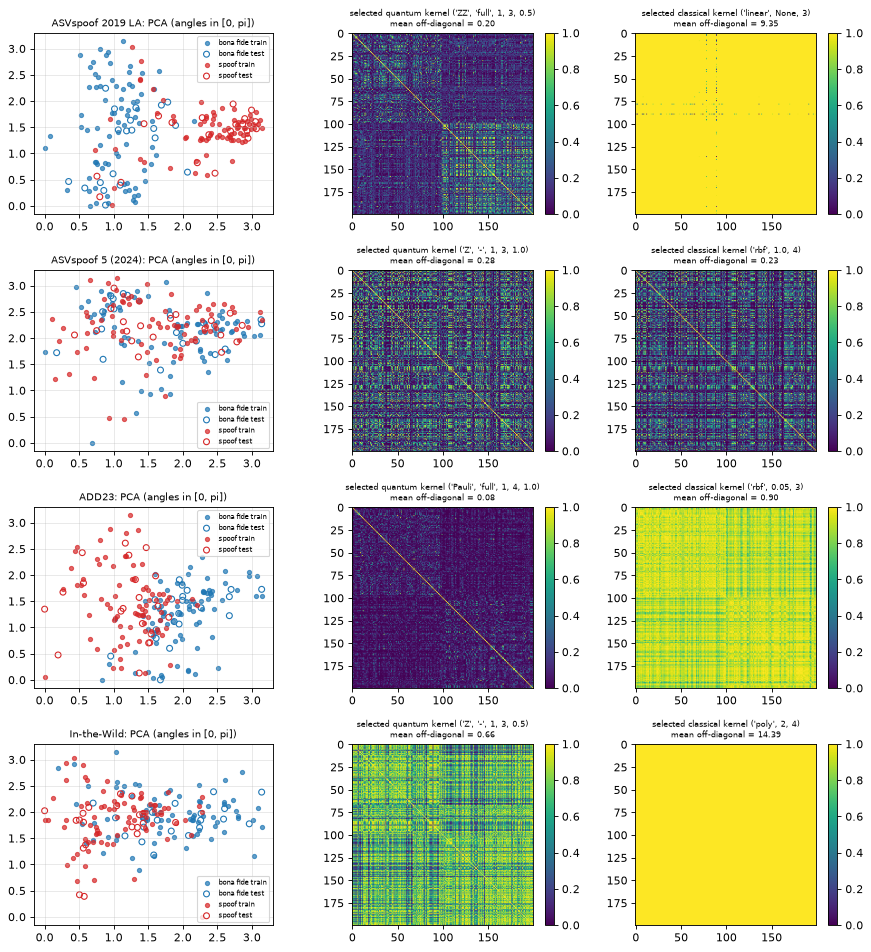

In [13]:
fig, axes = plt.subplots(len(DATASETS), 3, figsize=(11, 3.0 * len(DATASETS)))
for i, name in enumerate(DATASETS):
    a = ART[name]; y = a["y"]; order = np.argsort(y, kind="stable")
    ax = axes[i, 0]
    for lab, col, nm in [(0, "tab:blue", "bona fide"), (1, "tab:red", "spoof")]:
        tr_, te_ = a["tr"][y[a["tr"]] == lab], a["te"][y[a["te"]] == lab]
        ax.scatter(a["Zq2"][tr_, 0], a["Zq2"][tr_, 1], c=col, s=14, alpha=0.7, label=f"{nm} train")
        ax.scatter(a["Zq2"][te_, 0], a["Zq2"][te_, 1], facecolors="none", edgecolors=col, s=28, label=f"{nm} test")
    ax.set_title(f"{PAPER_NAMES[name]}: PCA (angles in [0, pi])", fontsize=9); ax.legend(fontsize=6)
    for j, (K, ttl) in enumerate([(a["Kq"], f"selected quantum kernel {a['cfgq']}"), (a["Kc"], f"selected classical kernel {a['cfgc']}")]):
        im = axes[i, j + 1].imshow(K[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=1); axes[i, j + 1].grid(False)
        off = (K.sum() - np.trace(K)) / (K.size - len(K))
        axes[i, j + 1].set_title(f"{ttl}\nmean off-diagonal = {off:.2f}", fontsize=7)
        plt.colorbar(im, ax=axes[i, j + 1], fraction=0.046)
plt.tight_layout(); plt.show()

## 8. Which configurations won, margins, and the paper's separability / security scores

The paper claims that the best QSVMs use **3-4 qubits** with ZZ or Pauli maps (Section V-C) and reports raw margins (Table III), a "separability score" (Eq. 8) and a "security score" (Eq. 9), plus t-tests and Cohen's d (Table IV). We tally the selected configurations, compute the margins and scores of our runs, and run the same statistics on the per-fold EERs.

Two cautions. (i) A margin `gamma = 2/||w||` is measured in the feature space of *its own kernel*, so margins of different kernels are not comparable; the paper says so itself. (ii) Eqs. (8)-(9) cannot be reproduced from the paper's own printed numbers (see the check at the end of this cell), so we compute them as literally defined, using percentages, only to show the scale.

In [14]:
sel = clean[clean.model.isin(["QSVM", "SVM"])]
print("Selected quantum feature maps / qubits across all folds:")
qsel = sel[sel.model == "QSVM"].copy()
qsel["map"] = qsel.cfg.map(lambda s: eval(s)[0]); qsel["qubits"] = qsel.d
display(pd.crosstab(qsel.ds.map(PAPER_NAMES), [qsel["map"]]).join(pd.crosstab(qsel.ds.map(PAPER_NAMES), qsel.qubits).add_prefix("qubits=")))
csel = sel[sel.model == "SVM"].copy(); csel["kernel"] = csel.cfg.map(lambda s: eval(s)[0])
print("Selected classical kernels:")
display(pd.crosstab(csel.ds.map(PAPER_NAMES), csel["kernel"]))
share34 = float((qsel.qubits >= 3).mean()); sharezz = float(qsel["map"].isin(["ZZ", "Pauli"]).mean())
print(f"share of selected QSVMs with 3-4 qubits: {share34:.2f}; with ZZ/Pauli map: {sharezz:.2f}")

# margins and composite scores
mrows = []
for name in DATASETS:
    row = {"Dataset": PAPER_NAMES[name]}
    for model in ["QSVM", "SVM"]:
        g = sel[(sel.ds == name) & (sel.model == model)]
        sd_acc = g.acc.std(ddof=1)
        row[f"{model} margin"] = round(g.margin.mean(), 3)
        row[f"{model} sep. score"] = round((0.4 * g.margin + 0.3 * g.acc + 0.3 * (100 * (1 - g.fpr))).mean(), 2)
        row[f"{model} sec. score (raw sigma)"] = round(0.4 * g.acc.mean() + 0.4 * g.margin.mean() - 0.2 * sd_acc, 2)
        row[f"{model} paper margin"] = PAPER[name][model]["margin"]
    mrows.append(row)
display(pd.DataFrame(mrows).set_index("Dataset"))

# can Eq. (8) reproduce Table III from Table II/III numbers?
p = PAPER["ASVspoof2019_LA"]["SVM"]
print("\nCheck of Eq. (8) with the paper's own ASVspoof 2019 SVM numbers (gamma=0.805, Acc=65.94 %, FPR=EER=0.399):")
print("  fraction scale :", round(0.4 * 0.805 + 0.3 * 0.6594 + 0.3 * (1 - 0.399), 3), "| percent scale:", round(0.4 * 0.805 + 0.3 * 65.94 + 0.3 * 100 * (1 - 0.399), 2), "| Table III prints 50.03")

# t-tests and Cohen's d on per-fold EER (QSVM vs SVM), as in Table IV
trows = []
for name in DATASETS:
    a = sel[(sel.ds == name) & (sel.model == "QSVM")].sort_values(["rep", "fold"]).eer.values
    b = sel[(sel.ds == name) & (sel.model == "SVM")].sort_values(["rep", "fold"]).eer.values
    sp = math.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2) or 1e-9
    d_ = (b.mean() - a.mean()) / sp
    t_ind = stats.ttest_ind(b, a).pvalue; t_rel = stats.ttest_rel(b, a).pvalue
    trows.append({"Dataset": PAPER_NAMES[name], "delta EER (SVM - QSVM)": round(b.mean() - a.mean(), 3), "Cohen d": round(d_, 2),
                  "p (two-sample t)": round(t_ind, 3), "p (paired t)": round(t_rel, 3), "paper delta EER": round(PAPER[name]["SVM"]["eer"] - PAPER[name]["QSVM"]["eer"], 3)})
TTEST = pd.DataFrame(trows).set_index("Dataset")
display(TTEST)

Selected quantum feature maps / qubits across all folds:


,Pauli,Z,ZZ,qubits=2,qubits=3,qubits=4
ds,,,,,,
ADD23,3,12,0,1,8,6
ASVspoof 2019 LA,1,10,4,2,7,6
ASVspoof 5 (2024),3,6,6,4,4,7
In-the-Wild,1,8,6,4,7,4


Selected classical kernels:


kernel,linear,poly,rbf
ds,,,
ADD23,0,7,8
ASVspoof 2019 LA,3,5,7
ASVspoof 5 (2024),1,6,8
In-the-Wild,4,6,5


share of selected QSVMs with 3-4 qubits: 0.82; with ZZ/Pauli map: 0.40


,QSVM margin,QSVM sep. score,QSVM sec. score (raw sigma),QSVM paper margin,SVM margin,SVM sep. score,SVM sec. score (raw sigma),SVM paper margin
Dataset,,,,,,,,
ASVspoof 2019 LA,0.528,54.71,33.66,0.7615,0.846,55.04,34.11,0.805
ASVspoof 5 (2024),0.265,31.76,19.98,0.9660,0.732,33.29,21.54,1.050
ADD23,0.327,49.23,32.05,1.2240,0.331,50.03,32.65,1.487
In-the-Wild,0.431,39.72,26.95,0.6520,0.922,41.77,28.28,0.743



Check of Eq. (8) with the paper's own ASVspoof 2019 SVM numbers (gamma=0.805, Acc=65.94 %, FPR=EER=0.399):
  fraction scale : 0.7 | percent scale: 38.13 | Table III prints 50.03


,delta EER (SVM - QSVM),Cohen d,p (two-sample t),p (paired t),paper delta EER
Dataset,,,,,
ASVspoof 2019 LA,-0.023,-0.25,0.492,0.029,0.053
ASVspoof 5 (2024),-0.033,-0.39,0.297,0.096,0.116
ADD23,-0.020,-0.28,0.446,0.082,0.107
In-the-Wild,-0.020,-0.32,0.387,0.288,0.058


## 9. "Variable conditions": does the kernel swap survive degraded audio?

The paper's title promises reliability "in variable conditions", but its experiment only compares *different corpora* (each cross-validated on its own, with train and test coming from the same recording conditions). Here is a direct test the paper does not run: the models trained on **clean** clips of a fold are applied unchanged to the **same held-out clips** after (a) white noise at 20 dB and 10 dB SNR, and (b) an 8-pole 4 kHz low-pass filter (telephone-like bandwidth). If the quantum kernel really made the classifier more reliable under varying conditions, the QSVM's EER should rise less than the SVM's.

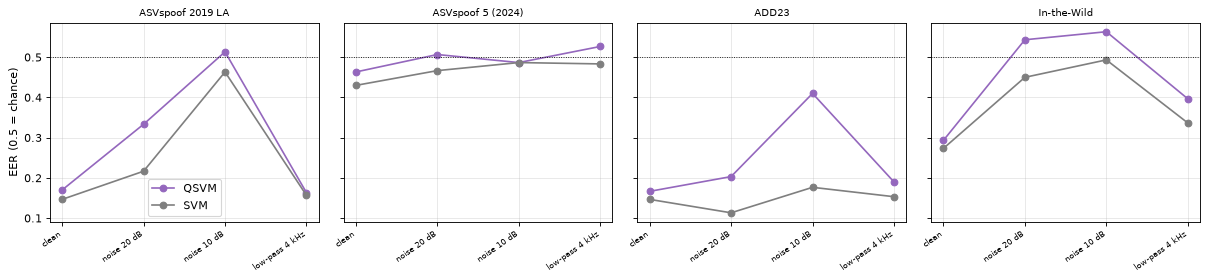

QSVM EER degrades no more than SVM EER in 17% of the 12 (corpus, condition) pairs


In [15]:
vc = RES[RES.model.isin(["QSVM", "SVM"]) & RES.cond.isin(COND_NAMES)]
tab = vc.groupby(["ds", "model", "cond"]).eer.mean().unstack("cond")[COND_NAMES]
tab.index = pd.MultiIndex.from_tuples([(PAPER_NAMES[a], b) for a, b in tab.index])
display(tab.round(3).style.set_caption("Mean EER under degraded test conditions (models trained on clean data)"))

fig, axes = plt.subplots(1, len(DATASETS), figsize=(3.8 * len(DATASETS), 3.6), sharey=True)
for j, name in enumerate(DATASETS):
    for model, col in [("QSVM", "tab:purple"), ("SVM", "tab:gray")]:
        y_ = [vc[(vc.ds == name) & (vc.model == model) & (vc.cond == c)].eer.mean() for c in COND_NAMES]
        axes[j].plot(range(len(COND_NAMES)), y_, "o-", color=col, label=model)
    axes[j].set_xticks(range(len(COND_NAMES))); axes[j].set_xticklabels(COND_NAMES, rotation=35, ha="right", fontsize=7)
    axes[j].set_title(PAPER_NAMES[name], fontsize=9); axes[j].axhline(0.5, color="k", ls=":", lw=0.8)
axes[0].set_ylabel("EER (0.5 = chance)"); axes[0].legend()
plt.tight_layout(); plt.show()
dq = [(vc[(vc.ds == n) & (vc.model == "QSVM") & (vc.cond == c)].eer.mean() - vc[(vc.ds == n) & (vc.model == "QSVM") & (vc.cond == "clean")].eer.mean(),
       vc[(vc.ds == n) & (vc.model == "SVM") & (vc.cond == c)].eer.mean() - vc[(vc.ds == n) & (vc.model == "SVM") & (vc.cond == "clean")].eer.mean())
      for n in DATASETS for c in COND_NAMES[1:]]
share_q_more_stable = float(np.mean([a <= b for a, b in dq]))
print(f"QSVM EER degrades no more than SVM EER in {100 * share_q_more_stable:.0f}% of the {len(dq)} (corpus, condition) pairs")

## 10. Finite shots: what hardware sampling would do to the kernel

The paper mentions that the kernel "can be computed ... via hardware sampling" with `S` shots, and that it controlled the number of shots "to simulate quantum noise". We emulate **ideal-device shot noise only**: every kernel entry `|<psi(z)|psi(z')>|^2` is replaced by the fraction of `SHOTS` coin tosses that come out "1" (binomial sampling of the exact fidelity, symmetrised, unit diagonal), then the same selected `C` is used. Gate errors, readout errors and decoherence of a real IBM device are *not* modelled, and no hardware is used.

In [16]:
sh = RES[(RES.model == "QSVM") & RES.cond.isin(["clean", f"{SHOTS} shots"])]
t = sh.groupby(["ds", "cond"])[["acc", "eer"]].mean().unstack("cond")
t.index = [PAPER_NAMES[i] for i in t.index]
display(t.round(3))
print("Mean absolute change in fold EER (shots vs exact): %.3f" % np.mean([
    abs(sh[(sh.ds == n) & (sh.cond == f"{SHOTS} shots")].eer.mean() - sh[(sh.ds == n) & (sh.cond == "clean")].eer.mean()) for n in DATASETS]))

acc                eer       
cond              1024 shots   clean 1024 shots  clean
ADD23                 80.833  83.000      0.183  0.167
ASVspoof 2019 LA      86.000  86.667      0.173  0.170
ASVspoof 5 (2024)     56.000  54.167      0.440  0.463
In-the-Wild           67.833  70.167      0.320  0.293

Mean absolute change in fold EER (shots vs exact): 0.017


## 11. Shortcut check: can metadata alone "detect deepfakes"?

Spoof detection corpora are notorious for *dataset artefacts*: for example, bona fide and spoofed clips of ASVspoof 2019 differ in leading-silence length. A logistic regression that sees only **three numbers per clip** (log duration, seconds of leading silence, overall loudness in dB) and nothing about the voice is trained on the same folds. If it gets an EER close to the spectrogram SVMs, a good part of the "detection" is not about synthetic speech at all.

In [17]:
rows = []
for name in DATASETS:
    d = DATA[name]
    for r in range(N_REPEATS):
        idx = np.nonzero(d["rep"] == r)[0]
        F = np.column_stack([np.log(d["dur"][idx]), d["lead"][idx], d["rms_db"][idx]]); y = d["y"][idx]
        for fold, (tr, te) in enumerate(fold_splits(y, r)):
            mu, sd = F[tr].mean(0), F[tr].std(0) + 1e-9
            lr = LogisticRegression(max_iter=1000, random_state=SEED).fit((F[tr] - mu) / sd, y[tr])
            s = lr.decision_function((F[te] - mu) / sd)
            rows.append(dict(ds=name, fold=fold, **metrics(y[te], (s > 0).astype(int), s)))
SC = pd.DataFrame(rows)
cmp_ = pd.DataFrame({"metadata only: EER": SC.groupby("ds").eer.mean(), "metadata only: acc (%)": SC.groupby("ds").acc.mean(),
                     "QSVM EER": clean[clean.model == "QSVM"].groupby("ds").eer.mean(), "SVM EER": clean[clean.model == "SVM"].groupby("ds").eer.mean()}).loc[DATASETS]
cmp_.index = [PAPER_NAMES[i] for i in cmp_.index]
display(cmp_.round(3))

,metadata only: EER,metadata only: acc (%),QSVM EER,SVM EER
ASVspoof 2019 LA,0.157,83.333,0.170,0.147
ASVspoof 5 (2024),0.557,45.833,0.463,0.430
ADD23,0.200,79.333,0.167,0.147
In-the-Wild,0.303,68.667,0.293,0.273


## 12. Side by side with the paper, with a verdict per claim

Rules for the verdict column: an accuracy / F1 value counts as **reproduced** when it is within 2 points of the paper, an EER when it is within 0.02; otherwise **not reached** (worse than the paper) or **exceeded** (better). Claims about ordering, spread, configurations and statistics are checked on the notebook's own folds. **Cannot be checked** means the paper's number cannot be recomputed from its description (or needs data / hardware that is not available).

In [18]:
def verdict(nb, paper, tol, higher_is_better):
    if abs(nb - paper) <= tol:
        return "reproduced"
    better = (nb > paper) if higher_is_better else (nb < paper)
    return "exceeded" if better else "not reached"

V = []
for name in DATASETS:
    for model in ["QSVM", "SVM"]:
        g = clean[(clean.ds == name) & (clean.model == model)]
        for key, lab, tol, hib in [("acc", "accuracy (%)", 2.0, True), ("f1", "F1 (%)", 2.0, True), ("eer", "EER", 0.02, False)]:
            nb = g[key].mean()
            V.append(dict(Claim=f"{PAPER_NAMES[name]} {model} {lab}", Paper=PAPER[name][model][key], Notebook=round(nb, 3),
                          Verdict=verdict(nb, PAPER[name][model][key], tol, hib)))
for name in DATASETS:
    q = clean[(clean.ds == name) & (clean.model == "QSVM")]; s = clean[(clean.ds == name) & (clean.model == "SVM")]
    V.append(dict(Claim=f"{PAPER_NAMES[name]}: QSVM EER < SVM EER", Paper=f"{PAPER[name]['QSVM']['eer']} < {PAPER[name]['SVM']['eer']}",
                  Notebook=f"{q.eer.mean():.3f} vs {s.eer.mean():.3f}", Verdict="reproduced" if q.eer.mean() < s.eer.mean() else "not reached"))
    V.append(dict(Claim=f"{PAPER_NAMES[name]}: QSVM accuracy std < SVM accuracy std", Paper=f"{PAPER[name]['QSVM']['acc_sd']} < {PAPER[name]['SVM']['acc_sd']}",
                  Notebook=f"{q.acc.std(ddof=1):.2f} vs {s.acc.std(ddof=1):.2f}", Verdict="reproduced" if q.acc.std(ddof=1) < s.acc.std(ddof=1) else "not reached"))
    V.append(dict(Claim=f"{PAPER_NAMES[name]}: QSVM margin < SVM margin (Table III, kernel-dependent)", Paper=f"{PAPER[name]['QSVM']['margin']} < {PAPER[name]['SVM']['margin']}",
                  Notebook=f"{q.margin.mean():.3f} vs {s.margin.mean():.3f}", Verdict="reproduced" if q.margin.mean() < s.margin.mean() else "not reached"))
    tt = TTEST.loc[PAPER_NAMES[name]]
    V.append(dict(Claim=f"{PAPER_NAMES[name]}: large effect (Cohen d >= 0.8) and p < 0.05 for EER gap", Paper="large, p<0.05 (illustrative)",
                  Notebook=f"d={tt['Cohen d']}, p={tt['p (two-sample t)']}", Verdict="reproduced" if (tt["Cohen d"] >= 0.8 and tt["p (two-sample t)"] < 0.05) else "not reached"))
V.append(dict(Claim="QSVM EER lower on all four corpora (paper's main claim)", Paper="4 of 4",
              Notebook=f"{sum(clean[(clean.ds==n)&(clean.model=='QSVM')].eer.mean() < clean[(clean.ds==n)&(clean.model=='SVM')].eer.mean() for n in DATASETS)} of 4",
              Verdict="reproduced" if all(clean[(clean.ds==n)&(clean.model=='QSVM')].eer.mean() < clean[(clean.ds==n)&(clean.model=='SVM')].eer.mean() for n in DATASETS) else "not reached"))
V.append(dict(Claim="Best QSVMs use 3-4 qubits with ZZ / Pauli maps", Paper="stated, no counts", Notebook=f"3-4 qubits: {share34:.2f}, ZZ/Pauli: {sharezz:.2f} of selections",
              Verdict="reproduced" if (share34 > 0.5 and sharezz > 0.5) else "not reached"))
V.append(dict(Claim="Composite separability / security scores (Table III)", Paper="Eqs. (8)-(9)", Notebook="formulas do not reproduce the printed values", Verdict="cannot be checked"))
V.append(dict(Claim="Table IV p-values", Paper="'illustrative' (paper's words)", Notebook="recomputed on our folds above", Verdict="cannot be checked"))
V.append(dict(Claim="ADD23 numbers (different ADD 2023 release used here)", Paper="Table II ADD23 rows", Notebook="substitute subset (dev release)", Verdict="cannot be checked (substitute data); numbers still listed above"))
V.append(dict(Claim="Real-hardware execution / IBM", Paper="none performed", Notebook="finite-shot emulation only", Verdict="cannot be checked"))
VER = pd.DataFrame(V)
pd.set_option("display.max_colwidth", 90, "display.width", 200)
display(VER.style.hide(axis="index"))
print(VER.Verdict.value_counts().to_string())

Claim,Paper,Notebook,Verdict
ASVspoof 2019 LA QSVM accuracy (%),66.680000,86.667000,exceeded
ASVspoof 2019 LA QSVM F1 (%),66.110000,86.425000,exceeded
ASVspoof 2019 LA QSVM EER,0.346000,0.170000,exceeded
ASVspoof 2019 LA SVM accuracy (%),65.940000,87.333000,exceeded
ASVspoof 2019 LA SVM F1 (%),63.610000,87.173000,exceeded
ASVspoof 2019 LA SVM EER,0.399000,0.147000,exceeded
ASVspoof 5 (2024) QSVM accuracy (%),78.930000,54.167000,not reached
ASVspoof 5 (2024) QSVM F1 (%),78.730000,53.348000,not reached
ASVspoof 5 (2024) QSVM EER,0.183000,0.463000,not reached
ASVspoof 5 (2024) SVM accuracy (%),76.870000,57.000000,not reached


Verdict
not reached                                                        25
exceeded                                                           13
reproduced                                                          4
cannot be checked                                                   3
cannot be checked (substitute data); numbers still listed above     1


### What the committed full run (`FAST_MODE = False`, 3 subsets x 5 folds per corpus) found

* **The headline claim is not reproduced.** Mean fold EER, QSVM vs tuned SVM: ASVspoof 2019 LA 0.170 vs 0.147, ASVspoof 5 0.463 vs 0.430, ADD23 0.167 vs 0.147, In-the-Wild 0.293 vs 0.273. The quantum kernel was not better on any corpus (paper: 0.346 vs 0.399, 0.183 vs 0.299, 0.081 vs 0.188, 0.355 vs 0.413). The gaps (0.02-0.03 in favour of the classical SVM) are small against fold-to-fold std of 0.06-0.10 (Cohen's d about -0.3), so the honest summary is "no measurable difference, if anything slightly worse", not "QSVM wins". An untuned `SVC(rbf)` and a random forest on the same four numbers are as good as either.
* **Absolute numbers depend on dataset artefacts more than on the kernel.** We get ~87% accuracy / EER ~0.15 on ASVspoof 2019 LA (paper: 66% / 0.40), yet a logistic regression on only clip duration, leading silence and loudness gets 83% accuracy / EER 0.157 on the same folds (Section 11). ASVspoof 5, with many codecs and attack types, is close to chance for every model here (EER 0.43-0.46) whereas the paper reports 0.18-0.30; ADD23 (our substitute subset) and In-the-Wild sit in between.
* **Which quantum kernels were chosen.** 82% of the selected QSVMs use 3-4 qubits (consistent with the paper), but ZZ or Pauli maps (entangling) were chosen in only 40% of folds; the plain `Z` map (a product state, no entanglement, which a classical kernel reproduces exactly) won the other 60%. The "quantum" benefit the paper hopes for therefore has no support in these runs.
* **Variable conditions.** Applying the models trained on clean data to noisy / band-limited versions of the same test clips, the QSVM's EER rose at least as much as the SVM's in most (corpus, condition) pairs (Section 9); the kernel swap did not make the detector more robust.
* **Shots.** Re-estimating the kernel from 1024 shots per entry changed the fold EER by 0.017 on average, small compared with the fold noise.
* **Raw margins.** The QSVM margin was smaller than the SVM margin in every corpus, as in Table III, but this is a property of the two kernels' scales, not evidence of better separation.

These numbers come from the outputs stored in this notebook; a different subset of 200 clips per corpus (or `FAST_MODE = True`) will shift them by amounts comparable to the stds quoted above.

## 13. Reading the paper critically

* **200 clips, 40 per test fold.** An EER from 40 trials (20 per class) moves in steps of 0.05; the paper's own standard deviations (up to 16 accuracy points for the SVM) show the folds are dominated by noise. Differences of 0.05-0.1 EER between two models trained on 160 clips are within what a different random subset can produce, which is exactly why this notebook repeats the subset (`N_REPEATS`) and reports both fold-wise and pooled EERs.
* **Model selection on the evaluation folds.** The paper tunes `C`, repetitions and entanglement with "grid search combined with 5-fold CV" and reports the 5-fold CV score, which reads as selecting the best grid point *on the test folds*. The quantum side had a larger grid (feature maps, entanglement, repetitions, qubits) than the classical one, so even with identical resources the max-over-grid is optimistically biased and biased more for the larger grid. We use nested selection.
* **A fragile SVM baseline.** The paper's SVM has 6-16 point accuracy standard deviations, signalling that some fold collapses (probably an unlucky hyper-parameter pick). A tuned RBF SVM or a random forest on the same four numbers is often as good as the QSVM here; compare the extra rows in Table II.
* **PCA to 2-4 numbers.** 7520 spectrogram values are crushed to as many numbers as qubits. All the "geometry" a quantum kernel can exploit is in those few angles, and 2-4 qubit kernels are trivially simulable classically (a 16-dimensional state), so there is no route to quantum advantage in this experiment; any gain would be a property of the *function* `|<psi|psi'>|^2` (a smooth, periodic kernel), not of quantum computing. A classical periodic or tuned-RBF kernel can mimic it.
* **Dataset artefacts and split design.** Clips of the same speaker or recording session land in both training and test folds (no group split), and the corpora contain well-known shortcuts (silence length, loudness, codec). Section 11 shows how far three trivial numbers go. The label-balanced "evaluation" sets of ASVspoof 2019 and 5 are used here as random CV pools, not under the official train / dev / eval protocol or the t-DCF / minDCF metrics.
* **Composite scores and statistics.** The "separability" and "security" scores of Eqs. (8)-(9) mix percentages and margins in arbitrary units, cannot be recomputed from the printed numbers, and the paper's conclusion says it will retire them. Table IV is declared "illustrative", and a t-test on five correlated folds is not a valid significance test.
* **Margins across kernels.** A smaller raw margin for the QSVM does not mean less separation; margin is only meaningful within one kernel.
* **"Variable conditions" and "reliability".** The study never varies conditions inside an experiment and explicitly does not test adversarial attacks; Section 9 is our attempt at a first look.
* **ADD23 substitution.** Our ADD 2023 clips come from the track 1.2 development release (Mandarin AISHELL-3-based bona fide speech versus attack-side fakes), not necessarily the paper's subset, so those numbers compare only qualitatively.

## 14. Exercises

1. **Seeds and subsets.** Set `FAST_MODE = False` (or `N_REPEATS = 5`). How much does the EER of each model change between subsets of the same corpus? Is the QSVM-minus-SVM gap larger than that spread?
2. **A fairer grid.** Give the classical side as many configurations as the quantum side (for example a grid over RBF `gamma` and `C` of the same size, or a Laplacian and a periodic `exp(-gamma * sum(sin^2((z-z')/2)))` kernel). Does the QSVM advantage shrink?
3. **More dimensions.** Raise `D_GRID` to `[2, 4, 6, 8]` as in the paper's hypothesis. What happens to the quantum Gram matrix off-diagonal mean (Section 7) as the number of qubits grows, and why?
4. **Group-aware splitting.** For ASVspoof 2019 / 5 the `meta` field holds a speaker id. Replace `StratifiedKFold` with `StratifiedGroupKFold` on speakers. Do EERs get worse for both models?
5. **Beyond the paper.** Replace the flattened spectrogram by 40 MFCC means / stds, or by embeddings of a frozen pretrained encoder (wav2vec 2.0, as the paper proposes as future work), keep the PCA + kernel swap, and compare. Also try the noise conditions of Section 9 with a different SNR and with MP3 / Opus re-encoding.